# Learning rate de la RNN bidireccional

¿Con qué learning rate aprende mejor `bidirectional_rnn`? Hoy usa `LEARNING_RATE = 1e-3` (el default de Adam).

El learning rate es el tamaño de cada paso de AdamW:

- **muy chico**: la loss baja lento y en pocas épocas la red queda sub-entrenada (la mejor época es la última);
- **muy grande**: los pasos se pasan del mínimo, la loss oscila o sube y el F1 se estanca;
- **bueno**: la loss de test baja rápido y se estabiliza.

Por eso además del F1 importan las **curvas por época**: muestran si a un `lr` le faltaron épocas o si es inestable.

Cada problema entrena con el weight decay que ya eligió (`bidirectional_rnn_weight_decay`: 0 en
capitalización, 1 en puntuación) y sin dropout. Ojo: AdamW achica los pesos `lr · λ` por paso, así que en
puntuación cambiar el `lr` también cambia cuánto regulariza el decay.

**Corre local, en CPU**: con 300 instancias por fuente y 15 épocas tarda ~12 minutos (5 learning rates × 2
problemas). Son menos datos que el pipeline (1000), así que el `lr` elegido acá hay que confirmarlo con
el pipeline completo antes de fijarlo.

## 1. Setup

In [4]:
import json
import logging
import os
import time
from datetime import datetime
from pathlib import Path
from typing import Any

# El notebook corre desde notebooks/hyperparameters/: subimos hasta la raíz del repo para importar src
while not Path("pyproject.toml").exists():
    os.chdir("..")

import matplotlib.pyplot as plt
import torch
from IPython.display import display
from torch.utils.data import DataLoader

from notebooks.hyperparameters.regularization.regularization_plots import (
    best_value,
    plot_control_f1,
    plot_gap,
    plot_loss_curves,
    summary_table,
)
from src.constants import MODELS_DIR, RUN_SEPARATOR
from src.data import build_loader, preprocess_dataset, split_dataset_dev_control, split_train_test
from src.features import EmbeddingsExtractor
from src.metrics.base import scores_from_tasks
from src.problem import CapitalizationProblem, Problem, PunctuationProblem
from src.training.neural import evaluate_problem_network, train_neural_model
from src.training.result import format_score

%matplotlib inline
# Solo warnings de src: el progreso lo imprime el notebook, una línea por entrenamiento
logging.basicConfig(level=logging.WARNING)
torch.set_num_threads(os.cpu_count() or 1)
print("Directorio:", Path.cwd(), "| GPU:", torch.cuda.is_available())

Directorio: /home/sebastian/personal/uba/Aprendizaje-Automatico-UBA/tp/TP2-Aprendizaje-Automatico-UBA | GPU: False


## 2. Configuración

In [5]:
PARAM = "learning_rate"
# Escala logarítmica alrededor del actual (1e-3): el efecto del lr es multiplicativo
LEARNING_RATES = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]

EPOCHS = 15
# Instancias por fuente. 300 ≈ 4.5 s por época en CPU; el pipeline usa 1000 (~3 veces más lento)
CAPITALIZATION_SIZE = 300
PUNCTUATION_SIZE = 300

PROBLEMS = [CapitalizationProblem(), PunctuationProblem()]
print(f"{len(LEARNING_RATES) * len(PROBLEMS)} entrenamientos de {EPOCHS} épocas")

10 entrenamientos de 15 épocas


## 3. Datos

Mismas fuentes, ventanas, splits y semilla que el pipeline: desarrollo/control y, dentro de desarrollo,
train/test. Se generan una sola vez y se reusan para todos los learning rates.

In [6]:
def problem_loaders(dataset) -> tuple[DataLoader, DataLoader, DataLoader]:
    """Train, test y control con los mismos splits que el pipeline"""
    development_set, control_set = split_dataset_dev_control(dataset)
    train_set, test_set = split_train_test(development_set)
    print(f"  train={len(train_set)} test={len(test_set)} control={len(control_set)}")
    return (
        build_loader(train_set, shuffle=True),
        build_loader(test_set, shuffle=False),
        build_loader(control_set, shuffle=False),
    )


punctuation_dataset, capitalization_dataset = preprocess_dataset(PUNCTUATION_SIZE, CAPITALIZATION_SIZE)
datasets = {"CapitalizationProblem": capitalization_dataset, "PunctuationProblem": punctuation_dataset}
loaders = {}
for problem in PROBLEMS:
    name = type(problem).__name__
    print(name)
    loaders[name] = problem_loaders(datasets[name])
extractor = EmbeddingsExtractor()

CapitalizationProblem
  train=1344 test=336 control=420
PunctuationProblem
  train=1344 test=336 control=420


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1710.05it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## 4. Barrido

In [7]:
def history_rows(result) -> list[dict[str, Any]]:
    """Loss y F1 de train y test de cada época"""
    return [
        {"epoch": m.epoch, "train_loss": m.loss, "test_loss": m.test_loss, "train_f1": m.score, "test_f1": m.test_score}
        for m in result.history
    ]


def train_with_lr(problem: Problem, learning_rate: float) -> dict[str, Any]:
    """Entrena la bidireccional del problema con ese lr y devuelve sus métricas"""
    train_loader, test_loader, control_loader = loaders[type(problem).__name__]
    model = problem.bidirectional_rnn_model()
    result = train_neural_model(
        train_loader, test_loader, extractor, problem.metric, model, n_epochs=EPOCHS,
        weight_decay=problem.bidirectional_rnn_weight_decay, learning_rate=learning_rate,
    )
    control = scores_from_tasks(evaluate_problem_network(result.model, control_loader, extractor, problem))
    return {"value": learning_rate, "best_epoch": result.best_epoch, "test_f1": result.score,
            "control_f1": control, "history": history_rows(result)}


stamp = datetime.now().strftime(f"%Y-%m-%d{RUN_SEPARATOR}%H-%M-%S")
OUT_DIR = Path(MODELS_DIR) / "learning_rate" / stamp
OUT_DIR.mkdir(parents=True, exist_ok=True)
report = {"config": {"learning_rates": LEARNING_RATES, "epochs": EPOCHS, "capitalization_size": CAPITALIZATION_SIZE,
                     "punctuation_size": PUNCTUATION_SIZE}, "problems": {}}

for problem in PROBLEMS:
    runs = report["problems"].setdefault(type(problem).__name__, [])
    for lr in LEARNING_RATES:
        start = time.time()
        runs.append(train_with_lr(problem, lr))
        run = runs[-1]
        print(f"{type(problem).__name__:22} lr={lr:<7g} mejor época={run['best_epoch']:>2}  "
              f"test: {format_score(run['test_f1'])}  ({time.time() - start:.0f} s)")
        (OUT_DIR / "results.json").write_text(json.dumps(report, indent=2))  # por si se corta
print("Resultados en", OUT_DIR)

CapitalizationProblem  lr=0.0001  mejor época=10  test: capitalizacion=0.226  (166 s)
CapitalizationProblem  lr=0.0003  mejor época=15  test: capitalizacion=0.315  (156 s)
CapitalizationProblem  lr=0.001   mejor época=14  test: capitalizacion=0.452  (148 s)
CapitalizationProblem  lr=0.003   mejor época=15  test: capitalizacion=0.632  (347 s)
CapitalizationProblem  lr=0.01    mejor época=14  test: capitalizacion=0.653  (448 s)
PunctuationProblem     lr=0.0001  mejor época= 2  test: punt_inicial=0.492 punt_final=0.233  (124 s)
PunctuationProblem     lr=0.0003  mejor época=15  test: punt_inicial=0.694 punt_final=0.361  (126 s)
PunctuationProblem     lr=0.001   mejor época=15  test: punt_inicial=0.748 punt_final=0.488  (106 s)
PunctuationProblem     lr=0.003   mejor época=11  test: punt_inicial=0.743 punt_final=0.528  (104 s)
PunctuationProblem     lr=0.01    mejor época= 6  test: punt_inicial=0.764 punt_final=0.509  (121 s)
Resultados en models/learning_rate/2026-11-16__17-37-34


## 5. Resultados

### Tabla

- **época**: la mejor en test. Si es la última (15), a ese `lr` le faltaron épocas.
- **brecha**: F1 de train − F1 de test en esa época.
- **test / control**: F1 macro promedio. Se elige con test; control confirma.

In [8]:
def show_and_save(fig, name: str) -> None:
    """Muestra el gráfico y lo guarda como PNG junto al results.json"""
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)


print(summary_table(report))


CapitalizationProblem
         valor           época          brecha            test         control  ctrl capitalizacion
        0.0001              10          -0.002           0.226           0.223           0.223
        0.0003              15           0.006           0.315           0.307           0.307
         0.001              14           0.227           0.452           0.449           0.449
         0.003              15           0.216           0.632           0.444           0.444
          0.01              14           0.197           0.653           0.568           0.568

PunctuationProblem
         valor           época          brecha            test         control  ctrl punt_inicial  ctrl punt_final
        0.0001               2           0.002           0.363           0.362           0.492           0.231
        0.0003              15          -0.003           0.527           0.515           0.676           0.355
         0.001              15           0.01

### Curvas de loss

Lo más informativo para el learning rate: con `lr` chico la loss baja lento y sin estabilizarse, con
`lr` grande baja rápido pero la de test (llena) se pone ruidosa o sube.

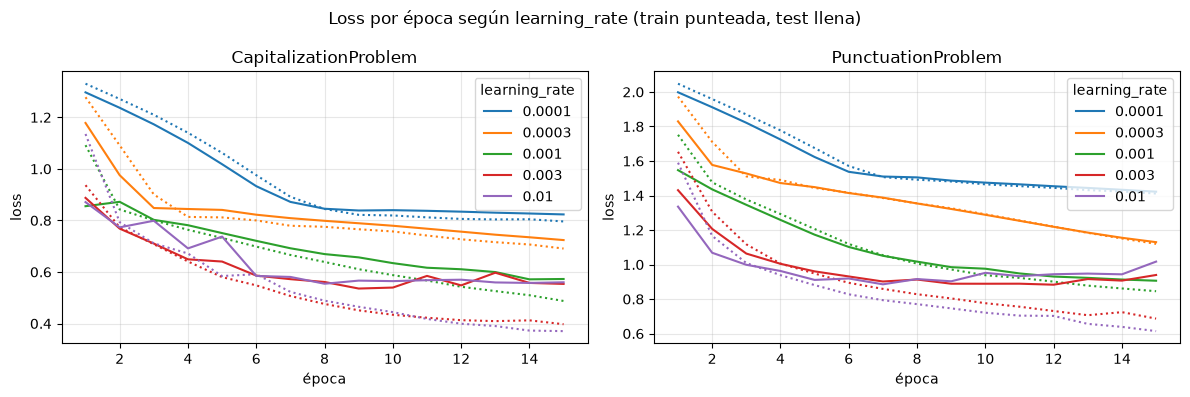

In [9]:
show_and_save(plot_loss_curves(report, PARAM), "loss_learning_rate")

### F1 de test por época

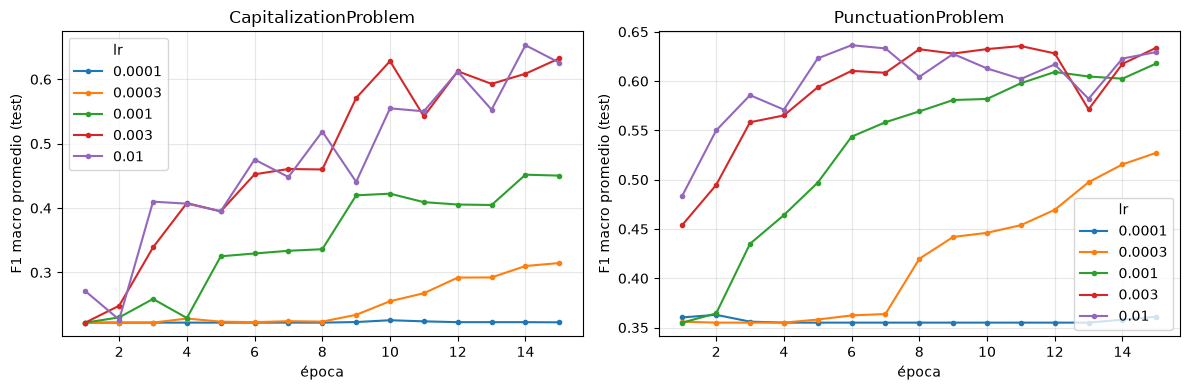

In [10]:
def plot_test_f1_curves(report: dict[str, Any]) -> plt.Figure:
    """F1 promedio de test en cada época, una curva por lr: qué tan rápido y estable aprende"""
    problems = report["problems"]
    fig, axes = plt.subplots(1, len(problems), figsize=(6 * len(problems), 4), squeeze=False)
    for ax, (problem, runs) in zip(axes[0], problems.items()):
        for run in runs:
            f1 = [sum(h["test_f1"].values()) / len(h["test_f1"]) for h in run["history"]]
            ax.plot(range(1, len(f1) + 1), f1, marker=".", label=f"{run['value']:g}")
        ax.set(title=problem, xlabel="época", ylabel="F1 macro promedio (test)")
        ax.grid(alpha=0.3)
        ax.legend(title="lr")
    fig.tight_layout()
    return fig


show_and_save(plot_test_f1_curves(report), "f1_test_por_epoca")

### F1 en control y sobreajuste

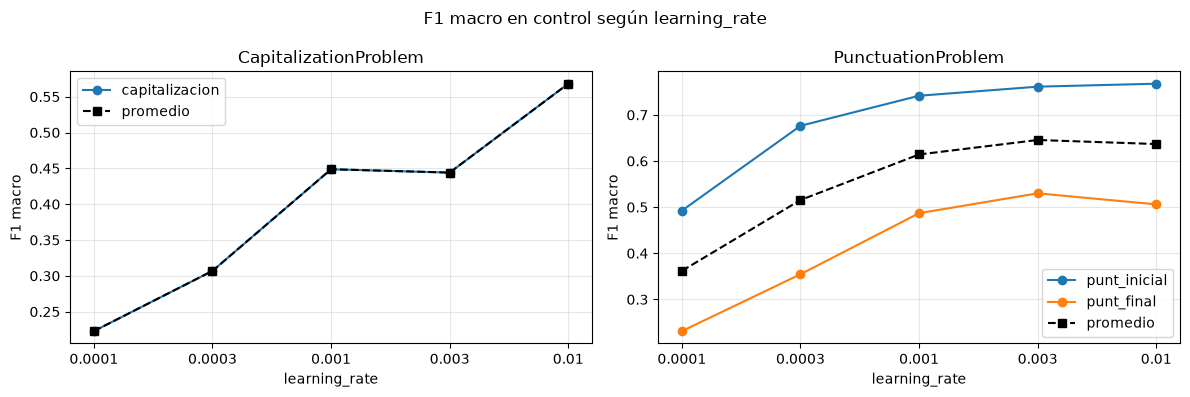

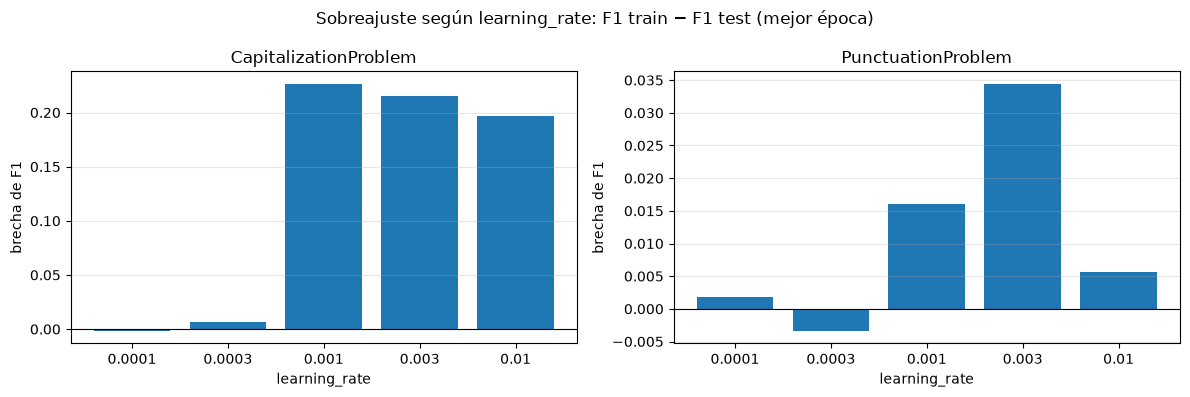

In [11]:
show_and_save(plot_control_f1(report, PARAM), "f1_control_learning_rate")
show_and_save(plot_gap(report, PARAM), "brecha_learning_rate")

## 6. Mejor learning rate por problema

In [12]:
for problem in report["problems"]:
    print(f"{problem}: lr = {best_value(report, problem):g} (test), {best_value(report, problem, 'control'):g} (control)")

CapitalizationProblem: lr = 0.01 (test), 0.01 (control)
PunctuationProblem: lr = 0.01 (test), 0.003 (control)


## 7. Conclusión

**El `lr` actual (`1e-3`) es chico para este entrenamiento: con `3e-3` la red aprende bastante más en las mismas
15 épocas.** Con 300 instancias por fuente hay ~7 batches por época (~105 pasos en total), y con `1e-3` las
curvas de F1 todavía suben en la época 15 en los dos problemas: la red no llega a converger.

| lr | Capitalización test / control | Puntuación test / control |
|---|---|---|
| 1e-4 | 0.226 / 0.223 | 0.363 / 0.362 |
| 3e-4 | 0.315 / 0.307 | 0.527 / 0.515 |
| 1e-3 (actual) | 0.452 / 0.449 | 0.618 / 0.614 |
| 3e-3 | 0.632 / 0.444 | **0.636 / 0.646** |
| 1e-2 | **0.653 / 0.568** | 0.636 / 0.637 |

- **`1e-4` no aprende**: el F1 queda plano (predice casi siempre la clase mayoritaria). `3e-4` aprende pero muy lento.
- **Puntuación → `3e-3`.** Empata con `1e-2` en test (0.636) y es mejor en control (0.646 vs 0.637). Con `1e-2` el
  mejor F1 llega en la época 6 y después la loss de test sube (1.02 al final): aprende rápido pero inestable y
  depende de quedarse con la época justa. `3e-3` llega al mismo F1 y se mantiene. Contra el actual: +0.018 en
  test y +0.032 en control.
- **Capitalización → `1e-2`, pero hay que confirmarlo.** Es el mejor en test (0.653) y control (0.568). Pero las
  curvas de `3e-3` y `1e-2` saltan mucho entre épocas (ej: `1e-2` cae de 0.55 a 0.44 en la época 9), siguen
  subiendo en la 15, y con `3e-3` test y control no coinciden (0.632 vs 0.444). Además `1e-2` es el extremo de
  la grilla: el óptimo puede estar más arriba.
- La brecha train − test sube con el `lr` en capitalización (~0.2 desde `1e-3`): al aprender más, sobreajusta
  más. Ahí sí puede ayudar la regularización (dropout).

**Limitaciones y siguiente paso.** El `lr` óptimo depende de cuántos pasos se entrena: con 1000 instancias por
fuente (pipeline) hay ~3 veces más pasos por época, y un `lr` más chico alcanza. Además, en puntuación el weight
decay efectivo es `lr · λ`, así que pasar a `3e-3` lo triplica. Antes de cambiar `LEARNING_RATE` hay que:

1. correr el pipeline completo (`--experiments bidirectional_rnn`) con `1e-3` y `3e-3`;
2. en capitalización, ampliar la grilla (`3e-3, 1e-2, 3e-2`) y entrenar más épocas, porque todavía no convergió.
